In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer

df = pd.read_csv("../data/diabetes_binary_classification_data.csv")

# Step 3 - Create TRAIN and TEST
- Split X and y into TRAIN and TEST.
- Use stratify=y so that TRAIN and TEST have approximately the same proportion of class 0 and class 1.
- Keep TEST separate until evaluation. Do not balance or resample TEST.


In [2]:
x = df.drop(columns=['Diabetes_binary'])
y = df['Diabetes_binary']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)


# Step 4 - Prepare the features
Prepare the input features using the information in the Understanding the Dataset guide and the preprocessing methods introduced
in the course. Your preprocessing choice should reflect whether a feature is numerical, binary categorical, or ordered categorical.
Briefly justify how you represent each type. There are no missing values in this dataset, so missing-value imputation is not
required.
- Use a Pipeline/ColumnTransformer where appropriate.
- Anything learned from the data during preprocessing must be learned from TRAIN only and then applied to TEST.


In [3]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]
binary_features = [
    "HighBP", 
    "HighChol", 
    "CholCheck", 
    "Smoker", 
    "Stroke", 
    "HeartDiseaseorAttack", 
    "PhysActivity", 
    "Fruits", 
    "Veggies", 
    "HvyAlcoholConsump", 
    "AnyHealthcare", 
    "NoDocbcCost", 
    "DiffWalk", 
    "Sex"
]
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("num", numeric_pipeline, numerical_features),
        ("bin", binary_pipeline, binary_features),
        ("ord", ordinal_pipeline, ordinal_features),
    ],
    remainder="drop"
)

def add_features(X):
    X = X.copy()
    X["ChronicCount"] = (X["HighBP"] + X["HighChol"]
                         + X["Stroke"] + X["HeartDiseaseorAttack"])
    X["LifestyleScore"] = (X["PhysActivity"] + X["Fruits"] + X["Veggies"] 
                           - X["Smoker"] - X["HvyAlcoholConsump"])

    return X
numerical_features += ["ChronicCount", "LifestyleScore"]


# Step 5 - Train Logistic Regression
Use Logistic Regression, as introduced in the classification lecture. Fit the complete Pipeline using TRAIN.
- Use model.predict(X_test) to obtain predicted classes.
- Use model.predict_proba(X_test)[:, 1] to obtain predicted probabilities for class 1.

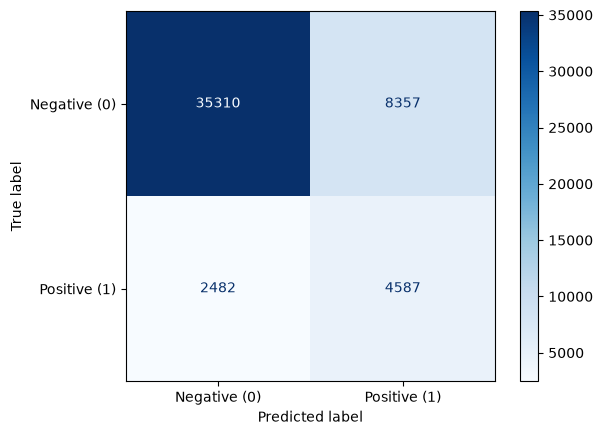

In [4]:
model = Pipeline(steps=[
    ("features", FunctionTransformer(add_features)),
    ("preprocess", preprocess),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

model.fit(x_train, y_train)
y_probs = model.predict_proba(x_test)[:, 1]
threshold = 0.6
y_pred = (y_probs >= threshold).astype(int)

cm = metrics.confusion_matrix(y_test, y_pred)
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative (0)', 'Positive (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

# Step 6 - Evaluate the model
Evaluate the Logistic Regression model on TEST using:
- confusion matrix;
- accuracy;
- precision;
- recall;
- F1 score.

Explain what a false positive and a false negative mean for this diabetes classification problem. Do not judge the model from
accuracy alone.

Accuracy: 0.79
Precission: 0.35
Recall: 0.65
False positive rate: 0.30
True positive rate: 0.63
Area Under the Curve: 0.82
F1: 0.46


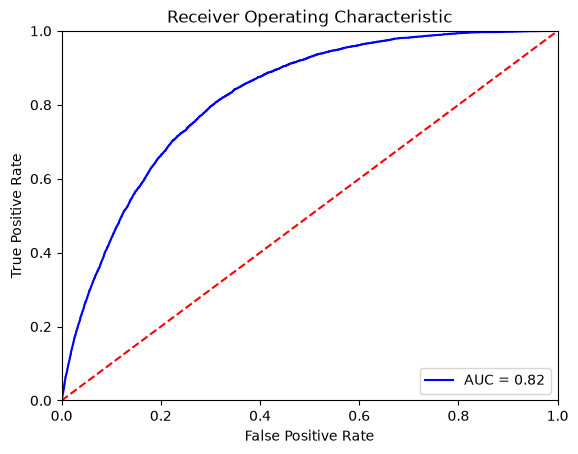

In [5]:
true_negative, false_positive, false_negative, true_positive = cm.ravel()

precission = true_positive / (true_positive + false_positive)
accuracy = (true_positive + true_negative) / (true_negative + false_positive + false_negative + true_positive)
recall = true_positive / (true_positive + false_negative)
print(f"Accuracy: {accuracy:.2f}")
print(f"Precission: {precission:.2f}")
print(f"Recall: {recall:.2f}")

fpr, tpr, threshold = metrics.roc_curve(y_test, y_probs)
roc_auc = metrics.auc(fpr, tpr)
f1 = 2*((precission * recall)/(precission+recall))

print(f"False positive rate: {fpr.mean():.2f}")
print(f"True positive rate: {tpr.mean():.2f}")
print(f"Area Under the Curve: {roc_auc:.2f}")
print(f"F1: {f1:.2f}")

plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

# Step 7 - Probability and threshold
Use the predicted probabilities from Logistic Regression to compare two decision thresholds:
- Threshold 0.50
- Threshold 0.40

For each threshold, calculate the confusion matrix, precision and recall. Compare the results. Explain what happened to false
positives, false negatives, precision and recall. Also explain what did NOT change when you changed only the threshold.


# Step 8 - Conclusion
- Summarize the most important things you learned from the EDA and the Logistic Regression results.
- Give at least two limitations of this analysis.
- Do not interpret an association as evidence that one feature causes diabetes.